# 02. Área 1: Campañas de Marketing (A1 - Supervisado)
**Materia:** INF432 - Sistemas para el Soporte a la Toma de Decisiones  
**Proyecto:** Minería de datos para decisiones comerciales - RetailMarket Santa Cruz  
**Autor (Integrante 1):** Diogo Nicolas Rodríguez Gómez (Reg. 221045686)  

### Pregunta de Negocio
Con un presupuesto limitado de contacto directo, ¿a qué clientes debe dirigirse la próxima campaña comercial para maximizar la tasa de aceptación (`Response` = 1) y minimizar el costo de adquisición de clientes?

### Metodología de Modelado (Requisito R5)
- **Modelos a comparar:** k-Nearest Neighbors (kNN), Naive Bayes Gaussiano y Árbol de Decisión.
- **Optimización:** Búsqueda en grilla con validación cruzada (`GridSearchCV`) sobre el conjunto de entrenamiento para kNN y Árbol de Decisión.
- **Evaluación:** Evaluación estricta sobre el conjunto de prueba (`test_scaled.csv`, 30% ciego) analizando la exactitud, matriz de confusión y el costo del negocio de falsos positivos vs. falsos negativos.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve
)

# Fijar semilla global obligatoria
SEMILLA = 1
np.random.seed(SEMILLA)

# 1. Cargar datos preprocesados desde data/processed/
train_df = pd.read_csv('data/processed/train_scaled.csv')
test_df = pd.read_csv('data/processed/test_scaled.csv')

# Separar atributos predictores (X) y variable objetivo (y)
X_train = train_df.drop(columns=['Response'])
y_train = train_df['Response']

X_test = test_df.drop(columns=['Response'])
y_test = test_df['Response']

print(f"Dimensiones de entrenamiento (X_train): {X_train.shape}")
print(f"Dimensiones de prueba (X_test): {X_test.shape}")


Dimensiones de entrenamiento (X_train): (1565, 28)
Dimensiones de prueba (X_test): (671, 28)


### 5.2.1 Modelo 1: k-Nearest Neighbors (kNN)
Optimizamos el hiperparámetro $k$ (`n_neighbors`) evaluando valores impares entre 3 y 25, y probando distancias euclidiana y manhattan con 5 pliegues de validación cruzada (`cv=5`).

In [2]:
# Grilla de hiperparámetros para kNN
param_grid_knn = {
    'n_neighbors': list(range(3, 27, 2)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn = KNeighborsClassifier()
grid_knn = GridSearchCV(knn, param_grid_knn, cv=5, scoring='f1', n_jobs=-1)
grid_knn.fit(X_train, y_train)

best_knn = grid_knn.best_estimator_
print("Parámetros óptimos para kNN:", grid_knn.best_params_)

# Predicciones sobre el conjunto de prueba
y_pred_knn = best_knn.predict(X_test)
y_prob_knn = best_knn.predict_proba(X_test)[:, 1]

acc_knn = accuracy_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)

print(f"kNN en Prueba -> Exactitud: {acc_knn:.4f} | F1-Score: {f1_knn:.4f} | AUC: {auc_knn:.4f}")

Parámetros óptimos para kNN: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
kNN en Prueba -> Exactitud: 0.8659 | F1-Score: 0.4512 | AUC: 0.7569


### 5.2.2 Modelo 2: Naive Bayes Gaussiano
El clasificador Naive Bayes asume independencia condicional entre los predictores y distribuciones normales en los atributos numéricos continuos. No requiere ajuste pesado de hiperparámetros y sirve como punto de referencia probabilístico rápido.

In [3]:
# Entrenar Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

# Predicciones en prueba
y_pred_nb = nb.predict(X_test)
y_prob_nb = nb.predict_proba(X_test)[:, 1]

acc_nb = accuracy_score(y_test, y_pred_nb)
rec_nb = recall_score(y_test, y_pred_nb)
prec_nb = precision_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)
auc_nb = roc_auc_score(y_test, y_prob_nb)

print(f"Naive Bayes en Prueba -> Exactitud: {acc_nb:.4f} | F1-Score: {f1_nb:.4f} | AUC: {auc_nb:.4f}")

Naive Bayes en Prueba -> Exactitud: 0.5246 | F1-Score: 0.3312 | AUC: 0.7570


### 5.2.3 Modelo 3: Árbol de Decisión (Decision Tree)
Optimizamos la profundidad máxima (`max_depth`), el criterio de partición (`gini` vs. `entropy`) y el número mínimo de muestras por hoja (`min_samples_leaf`) para evitar el sobreajuste (*overfitting*) y obtener reglas interpretables de negocio.

In [4]:
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 8, 10],
    'min_samples_leaf': [5, 10, 15, 20]
}

dt = DecisionTreeClassifier(random_state=SEMILLA)
grid_dt = GridSearchCV(dt, param_grid_dt, cv=5, scoring='f1', n_jobs=-1)
grid_dt.fit(X_train, y_train)

best_dt = grid_dt.best_estimator_
print("Parámetros óptimos para Árbol de Decisión:", grid_dt.best_params_)

# Predicciones en prueba
y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

acc_dt = accuracy_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

print(f"Árbol de Decisión en Prueba -> Exactitud: {acc_dt:.4f} | F1-Score: {f1_dt:.4f} | AUC: {auc_dt:.4f}")

Parámetros óptimos para Árbol de Decisión: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 15}
Árbol de Decisión en Prueba -> Exactitud: 0.8629 | F1-Score: 0.4390 | AUC: 0.8072


### 5.2.4 Comparación de Modelos y Matrices de Confusión
Evaluamos las matrices de confusión de los tres modelos en el conjunto de prueba para contrastar los **Falsos Positivos (FP)** (costo de contactar a un cliente que no compra) y los **Falsos Negativos (FN)** (costo de oportunidad por perder un cliente que sí habría aceptado la oferta).

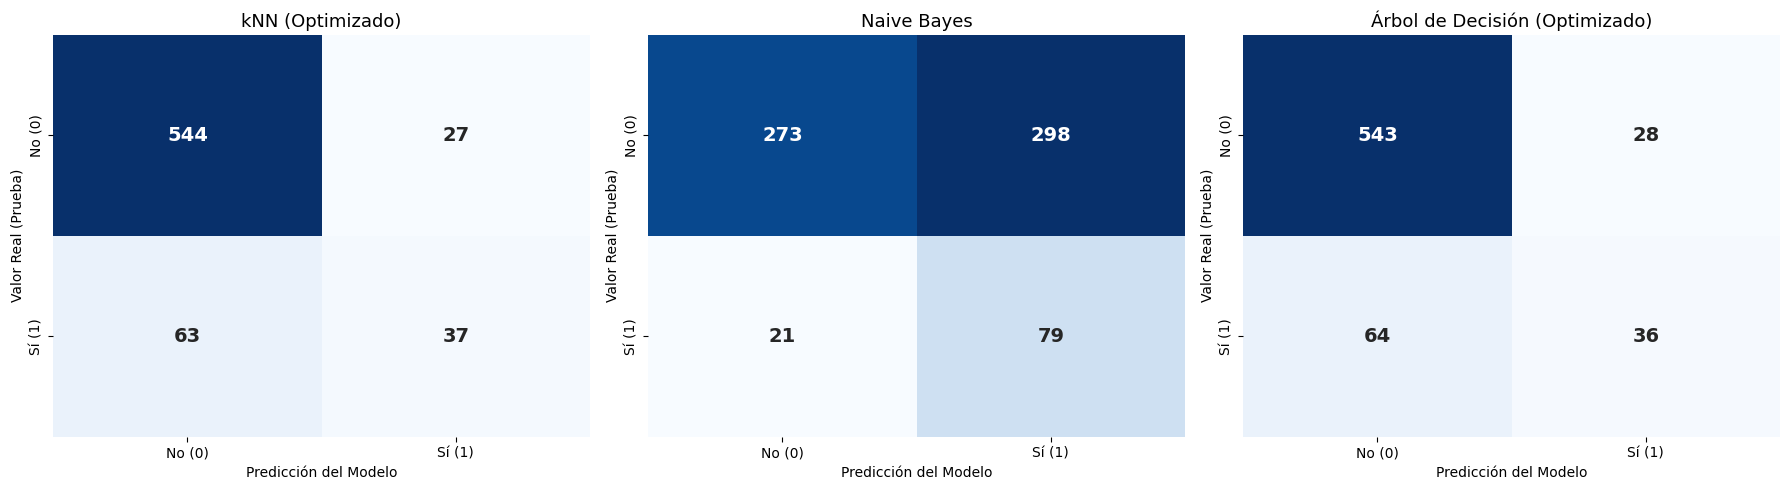

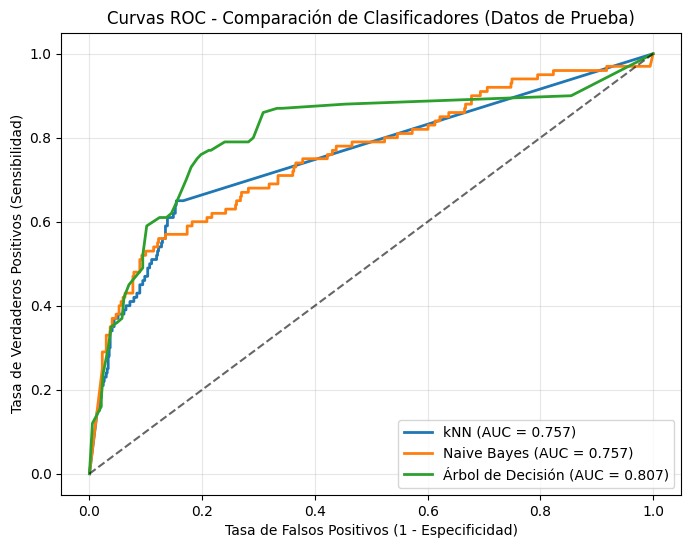

In [5]:
# 1. Gráfico de Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos_dict = {
    'kNN (Optimizado)': (y_pred_knn, axes[0]),
    'Naive Bayes': (y_pred_nb, axes[1]),
    'Árbol de Decisión (Optimizado)': (y_pred_dt, axes[2])
}

for nombre, (preds, ax) in modelos_dict.items():
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_title(nombre, fontsize=13)
    ax.set_xlabel('Predicción del Modelo')
    ax.set_ylabel('Valor Real (Prueba)')
    ax.set_xticklabels(['No (0)', 'Sí (1)'])
    ax.set_yticklabels(['No (0)', 'Sí (1)'])

plt.tight_layout()
plt.savefig('reports/figures/matrices_confusion_A1.png', dpi=300)
plt.show()

# 2. Curvas ROC comparativas
plt.figure(figsize=(8, 6))
for nombre, probas in [('kNN', y_prob_knn), ('Naive Bayes', y_prob_nb), ('Árbol de Decisión', y_prob_dt)]:
    fpr, tpr, _ = roc_curve(y_test, probas)
    auc = roc_auc_score(y_test, probas)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6)
plt.title('Curvas ROC - Comparación de Clasificadores (Datos de Prueba)')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.savefig('reports/figures/curvas_roc_A1.png', dpi=300)
plt.show()

### 5.2.5 Resumen de Rendimiento y Análisis Económico de Errores
Construimos la tabla consolidada en los datos de prueba y calculamos los porcentajes exactos de Falsos Positivos y Falsos Negativos requeridos para la plantilla del documento.

In [6]:
# Función para calcular porcentajes de FP y FN sobre el total de prueba
def calcular_tasas_error(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = len(y_true)
    pct_fp = (fp / total) * 100
    pct_fn = (fn / total) * 100
    return pct_fp, pct_fn

fp_knn, fn_knn = calcular_tasas_error(y_test, y_pred_knn)
fp_nb, fn_nb = calcular_tasas_error(y_test, y_pred_nb)
fp_dt, fn_dt = calcular_tasas_error(y_test, y_pred_dt)

# Armar dataframe consolidado
df_resultados_a1 = pd.DataFrame({
    'Modelo': ['kNN', 'Naive Bayes', 'Árbol de decisión'],
    'Parámetros óptimos': [
        f"k = {grid_knn.best_params_['n_neighbors']}, metric = '{grid_knn.best_params_['metric']}'",
        '— (GaussianNB estándar)',
        f"criterion = '{grid_dt.best_params_['criterion']}', max_depth = {grid_dt.best_params_['max_depth']}, min_leaf = {grid_dt.best_params_['min_samples_leaf']}"
    ],
    'Exactitud en prueba': [f"{acc_knn:.2%}", f"{acc_nb:.2%}", f"{acc_dt:.2%}"],
    '% falsos positivos': [f"{fp_knn:.2f}%", f"{fp_nb:.2f}%", f"{fp_dt:.2f}%"],
    '% falsos negativos': [f"{fn_knn:.2f}%", f"{fn_nb:.2f}%", f"{fn_dt:.2f}%"],
    'F1-Score': [f"{f1_knn:.4f}", f"{f1_nb:.4f}", f"{f1_dt:.4f}"],
    'AUC-ROC': [f"{auc_knn:.4f}", f"{auc_nb:.4f}", f"{auc_dt:.4f}"]
})

print("=== TABLA PARA EL DOCUMENTO WORD (SECCIÓN 5.2.3) ===")
display(df_resultados_a1)

=== TABLA PARA EL DOCUMENTO WORD (SECCIÓN 5.2.3) ===


,Modelo,Parámetros óptimos,Exactitud en prueba,% falsos positivos,% falsos negativos,F1-Score,AUC-ROC
0,kNN,"k = 3, metric = 'manhattan'",86.59%,4.02%,9.39%,0.4512,0.7569
1,Naive Bayes,— (GaussianNB estándar),52.46%,44.41%,3.13%,0.3312,0.7570
2,Árbol de decisión,"criterion = 'gini', max_depth = 10, min_leaf = 15",86.29%,4.17%,9.54%,0.4390,0.8072


### 5.2.6 Importancia de Variables en el Árbol de Decisión
Extraemos las variables con mayor peso predictivo según el Árbol de Decisión para traducir el hallazgo técnico a recomendaciones accionables para el equipo comercial de RetailMarket Santa Cruz.

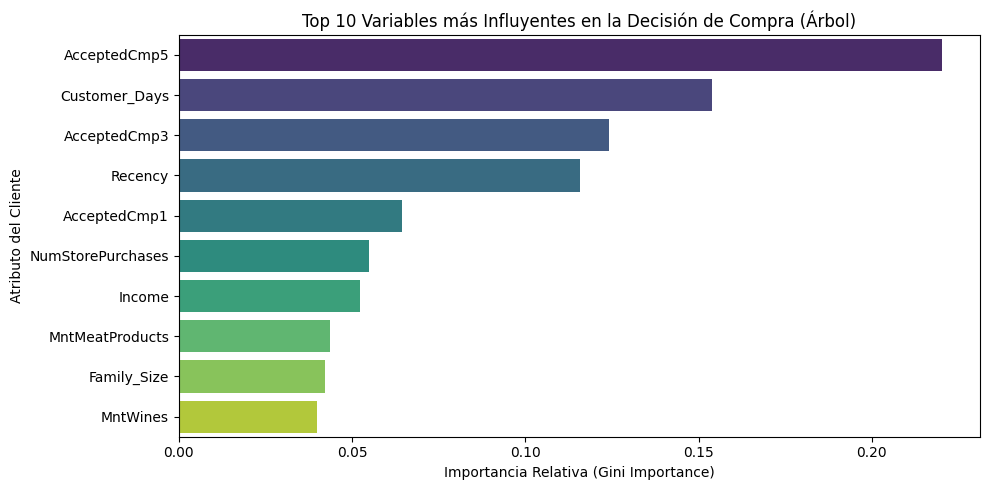

Top 5 variables más críticas para el negocio:


In [7]:
importancias = pd.Series(best_dt.feature_importances_, index=X_train.columns)
importancias_top10 = importancias.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=importancias_top10.values, y=importancias_top10.index, hue=importancias_top10.index, palette='viridis', legend=False)
plt.title('Top 10 Variables más Influyentes en la Decisión de Compra (Árbol)')
plt.xlabel('Importancia Relativa (Gini Importance)')
plt.ylabel('Atributo del Cliente')
plt.tight_layout()
plt.savefig('reports/figures/importancia_variables_A1.png', dpi=300)
plt.show()

print("Top 5 variables más críticas para el negocio:")
